In [40]:
from pathlib import Path
import pandas as pd
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Telco-Customer-Churn.txt"
print("File exists: ", DATA_PATH.exists())

File exists:  True


In [41]:
with open(DATA_PATH, 'r', encoding='utf-8') as file:
    for _ in range(5):
        print(file.readline().rstrip())

customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3,1840.75,No


In [42]:
df = pd.read_csv(DATA_PATH, sep = ',')
print("shape :", df.shape)
display(df.head())

shape : (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [43]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [44]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [45]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [46]:
print(df["TotalCharges"].dtype)

str


In [47]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"], errors='coerce')

In [48]:
print(df["TotalCharges"].dtype)
print("Missing total charges", df["TotalCharges"].isnull().sum())

float64
Missing total charges 11


In [49]:
print("Duplicate rows:",df.duplicated().sum())
print("Duplicate customer IDs", df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs 0


In [50]:
display(df[df["TotalCharges"].isnull()])

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [51]:
df.loc[df["TotalCharges"].isnull(), ['tenure', 'MonthlyCharges', 'TotalCharges' ]]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [52]:
df = df.dropna(subset = ["TotalCharges"]).copy()
print("Shape after cleaning", df.shape)
print("Missing values remaining", df.isnull().sum().sum())

Shape after cleaning (7032, 21)
Missing values remaining 0


In [53]:
x = df.drop(columns = ["customerID", "Churn"])

In [54]:
y = df["Churn"]

In [55]:
print("Features shape", x.shape)
print("Target shape", y.shape)

Features shape (7032, 19)
Target shape (7032,)


In [56]:
print(y.value_counts())

Churn
No     5163
Yes    1869
Name: count, dtype: int64


In [57]:
print(y.value_counts(normalize = True).round(3)*100)

Churn
No     73.4
Yes    26.6
Name: proportion, dtype: float64


Text(0.5, 1.0, 'Customer Church Distribution')

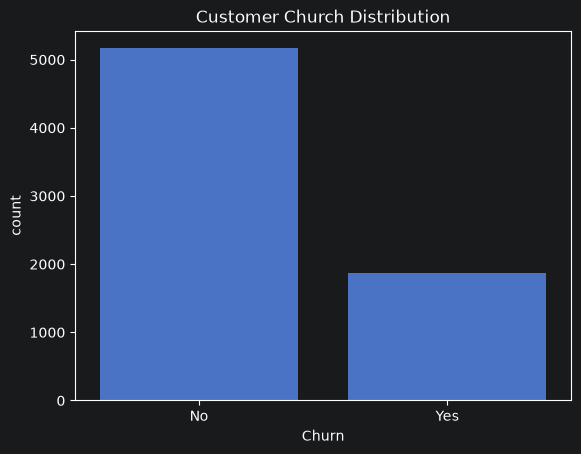

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(data = df, x="Churn")
plt.title("Customer Church Distribution")

In [59]:
numeric_features = x.select_dtypes(include = ["float64", "int64"]).columns.tolist()
categorical_features = x.select_dtypes(include = ["category", "object", "bool", "str"]).columns.tolist()
print("Numerical features",numeric_features)
print("Categorical features",categorical_features)

Numerical features ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [60]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy = "most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown = "ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cag", categorical_pipeline, categorical_features)
])
print("numerical features pipline steps", numeric_pipeline.steps)
print("categorical features pipline steps", categorical_pipeline.steps)
print(preprocessor)

numerical features pipline steps [('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]
categorical features pipline steps [('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))]
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges',
                                  'TotalCharges']),
                                ('cag',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
 

In [61]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

In [62]:
print("X train shape", X_train.shape)
print("X test shape", X_test.shape)
print("y train shape", y_train.shape)
print("y test shape", y_test.shape)

X train shape (5625, 19)
X test shape (1407, 19)
y train shape (5625,)
y test shape (1407,)


In [63]:
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)
print("Processed training shape", X_train_preprocessed.shape)
print("Processed testing shape", X_test_preprocessed.shape)


Processed training shape (5625, 45)
Processed testing shape (1407, 45)


In [64]:
from sklearn.dummy import DummyClassifier
dummy_clf = DummyClassifier(strategy = "most_frequent")
dummy_clf.fit(X_train_preprocessed, y_train)
y_pred_baseline = dummy_clf.predict(X_test_preprocessed)


In [65]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix)
print("Baseline accuracy", accuracy_score(y_test, y_pred_baseline))
print("Baseline precision", precision_score(y_test, y_pred_baseline, pos_label = "Yes", zero_division = 0))
print("Baseline recall", recall_score(y_test, y_pred_baseline, pos_label = "Yes",zero_division = 0))
print("Baseline F1-Score", f1_score(y_test, y_pred_baseline, pos_label = "Yes",zero_division = 0))
print("\n confusion matrix")
print(confusion_matrix(y_test, y_pred_baseline, labels = ["No", "Yes"]))


Baseline accuracy 0.7341862117981521
Baseline precision 0.0
Baseline recall 0.0
Baseline F1-Score 0.0

 confusion matrix
[[1033    0]
 [ 374    0]]


In [66]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
logistic_model = Pipeline([
    ("processor", preprocessor),
    ("classifier", LogisticRegression(max_iter= 1000, random_state = 24))
])

logistic_model.fit(X_train, y_train)
y_pred_logistic = logistic_model.predict(X_test)

In [67]:
print("Logistic regression accuracy", accuracy_score(y_test, y_pred_logistic))
print("Logistic regression precision", precision_score(y_test, y_pred_logistic, pos_label = "Yes", zero_division = 0))
print("Logistic regression recall", recall_score(y_test, y_pred_logistic, pos_label = "Yes",zero_division = 0))
print("Logistic regression F1-Score", f1_score(y_test, y_pred_logistic, pos_label = "Yes",zero_division = 0))
print("Logistic regression classification report\n", classification_report(y_test, y_pred_logistic, zero_division = 0))
print("\n confusion matrix")
print(confusion_matrix(y_test, y_pred_logistic, labels = ["No" , "Yes"]))

Logistic regression accuracy 0.8038379530916845
Logistic regression precision 0.6484848484848484
Logistic regression recall 0.5721925133689839
Logistic regression F1-Score 0.6079545454545454
Logistic regression classification report
               precision    recall  f1-score   support

          No       0.85      0.89      0.87      1033
         Yes       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407


 confusion matrix
[[917 116]
 [160 214]]


In [68]:
churn_probabilities = logistic_model.predict_proba(X_test)[:,1]
print("Minimum:", churn_probabilities.min())
print("Maximum:", churn_probabilities.max())
print("Average:", churn_probabilities.mean())
print("\n first 10 churn probabilities:")
print(churn_probabilities[:10])


Minimum: 0.0014413956223375515
Maximum: 0.8474657995951943
Average: 0.2726629718757723

 first 10 churn probabilities:
[0.01751303 0.59192131 0.00482103 0.20165167 0.1015014  0.4718449
 0.02651812 0.16543101 0.67959955 0.01552463]


In [69]:
print(logistic_model.classes_)

['No' 'Yes']


In [70]:
import pandas as pd
results = pd.DataFrame({
    "Models": ["Baseline", "Logistic regression"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_baseline),
        accuracy_score(y_test, y_pred_logistic)
    ],
    "Precession": [
        precision_score(y_test, y_pred_baseline, pos_label = "Yes", zero_division = 0),
        precision_score(y_test, y_pred_logistic, pos_label = "Yes", zero_division = 0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_baseline, pos_label = "Yes", zero_division = 0),
        recall_score(y_test, y_pred_logistic, pos_label = "Yes", zero_division = 0)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_baseline, pos_label = "Yes", zero_division = 0),
        f1_score(y_test, y_pred_logistic, pos_label = "Yes", zero_division = 0)
    ]
})
results

,Models,Accuracy,Precession,Recall,F1-Score
0,Baseline,0.734186,0.000000,0.000000,0.000000
1,Logistic regression,0.803838,0.648485,0.572193,0.607955


In [71]:
churn_probabilities = logistic_model.predict_proba(X_test)[:,1]

results = []
thresholds = [0.3, 0.4, 0.5, 0.6]

for threshold in thresholds:
    y_pred = (churn_probabilities >= threshold).astype(int)
    y_pred = pd.Series(y_pred).map({0: "No", 1: "Yes"})
    results.append({
        "threshold": threshold,
        "precision": precision_score(y_test, y_pred, pos_label = "Yes", zero_division = 0),
        "recall": recall_score(y_test, y_pred, pos_label = "Yes", zero_division = 0),
        "f1_score": f1_score(y_test, y_pred, pos_label = "Yes", zero_division = 0)
    }
    )
threshold_results = pd.DataFrame(results)
threshold_results

,threshold,precision,recall,f1_score
0,0.3,0.510791,0.759358,0.610753
1,0.4,0.579186,0.684492,0.627451
2,0.5,0.648485,0.572193,0.607955
3,0.6,0.679245,0.385027,0.491468


In [72]:
from sklearn.ensemble import RandomForestClassifier
rf_model = Pipeline([
    ("processor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators= 200, random_state = 42, class_weight = "balanced", n_jobs = 1))
])

In [73]:
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

In [74]:
print("Random forest accuracy", accuracy_score(y_test, y_pred_rf))
print("Random forest precision", precision_score(y_test, y_pred_rf, pos_label = "Yes", zero_division = 0))
print("Random forest recall", recall_score(y_test, y_pred_rf, pos_label = "Yes",zero_division = 0))
print("Random forest F1-Score", f1_score(y_test, y_pred_rf, pos_label = "Yes",zero_division = 0))
print("Random forest classification report\n", classification_report(y_test, y_pred_rf, zero_division = 0))
print("\n confusion matrix")
print(confusion_matrix(y_test, y_pred_rf, labels = ["No" , "Yes"]))

Random forest accuracy 0.767590618336887
Random forest precision 0.5535307517084282
Random forest recall 0.6497326203208557
Random forest F1-Score 0.5977859778597786
Random forest classification report
               precision    recall  f1-score   support

          No       0.86      0.81      0.84      1033
         Yes       0.55      0.65      0.60       374

    accuracy                           0.77      1407
   macro avg       0.71      0.73      0.72      1407
weighted avg       0.78      0.77      0.77      1407


 confusion matrix
[[837 196]
 [131 243]]


In [75]:
model_result = pd.DataFrame([
    {
    "Model" : "Logistic Regression",
    "Accuracy" : accuracy_score(y_test, y_pred_logistic),
    "Precision" : precision_score(y_test, y_pred_logistic, pos_label = "Yes",zero_division = 0),
    "Recall" : recall_score(y_test, y_pred_logistic, pos_label = "Yes",zero_division = 0),
    "F1_Score" : f1_score(y_test, y_pred_logistic, pos_label = "Yes",zero_division = 0)
    },
    {
    "Model" : "Random Forest",
    "Accuracy" : accuracy_score(y_test, y_pred_rf),
    "Precision" : precision_score(y_test, y_pred_rf, pos_label = "Yes",zero_division = 0),
    "Recall" : recall_score(y_test, y_pred_rf, pos_label = "Yes",zero_division = 0),
    "F1_Score" : f1_score(y_test, y_pred_rf, pos_label = "Yes",zero_division = 0)
    }
    ])
model_result

,Model,Accuracy,Precision,Recall,F1_Score
0,Logistic Regression,0.803838,0.648485,0.572193,0.607955
1,Random Forest,0.767591,0.553531,0.649733,0.597786


In [76]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer
import numpy as np

cv = StratifiedKFold( n_splits = 5 , shuffle = True, random_state = 42)

scoring = {
    "accuracy": "accuracy",
    "precision " : make_scorer(
        precision_score,
        pos_label = "Yes",
        zero_division = 0
    ),
    "recall" : make_scorer(
        recall_score,
        pos_label = "Yes",
        zero_division = 0
    ),
    "f1_score": make_scorer(
        f1_score,
        pos_label = "Yes",
        zero_division = 0
    ),
    "roc_auc": "roc_auc"
    }

logistic_cv = cross_validate( logistic_model, X_train, y_train, cv = cv, scoring = scoring, n_jobs = 1)
rf_cv = cross_validate( rf_model, X_train, y_train, cv = cv, scoring = scoring, n_jobs = 1)

In [77]:
def cv_summarize (cv_results, model_name):
    summary = {}
    for metric in scoring:
        values = cv_results[f"test_{metric}"]
        summary[f"{metric}_mean"] = values.mean()
        summary[f"{metric}_std"] = values.std
    return pd.Series(summary, name = model_name)
cv_comparison = pd.DataFrame([
    cv_summarize(logistic_cv, "Logistic Regression"),
    cv_summarize(rf_cv, "Random Forest")
])


In [78]:
def cv_summarize (cv_results, model_name):
    summary = {}
    for metric in scoring:
        values = cv_results[f"test_{metric}"]
        summary[f"{metric}_mean"] = values.mean()
        summary[f"{metric}_std"] = values.std()
    return pd.Series(summary, name = model_name)
cv_comparison = pd.DataFrame([
    cv_summarize(logistic_cv, "Logistic Regression"),
    cv_summarize(rf_cv, "Random Forest")
])
cv_comparison.round(4)

,accuracy_mean,accuracy_std,precision _mean,precision _std,recall_mean,recall_std,f1_score_mean,f1_score_std,roc_auc_mean,roc_auc_std
Logistic Regression,0.8025,0.0116,0.6541,0.0289,0.5465,0.0229,0.5953,0.0229,0.8461,0.0052
Random Forest,0.7746,0.0101,0.5668,0.0165,0.6435,0.0251,0.6027,0.0195,0.8253,0.0073


In [79]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_distributions = {
    "classifier__n_estimators" : randint(100, 600),
    "classifier__max_depth" : [None, 5, 10, 15, 20, 30],
    "classifier__min_samples_split" : randint(2,20),
    "classifier__min_samples_leaf" : randint(1, 10),
    "classifier__max_features" : ["sqrt", "log2", None],
    "classifier__class_weight" : ["balanced", "balanced_subsample"]
}

In [80]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state = 42,
        n_jobs = -1
    ))
])

cv = StratifiedKFold(n_splits = 5, shuffle= True, random_state = 42)

f1_scorer = make_scorer(
    f1_score,
    pos_label = "Yes",
    zero_division = 0
)

rf_search = RandomizedSearchCV(
    estimator = rf_pipeline,
    param_distributions = param_distributions,
    n_iter = 30,
    cv = cv,
    scoring = f1_scorer,
    random_state = 42,
    n_jobs = -1,
    verbose = 1,
    error_score = "raise"
)


In [81]:
rf_search.fit(X_train, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__class_weight': ['balanced', 'balanced_subsample'], 'classifier__max_depth': [None, 5, ...], 'classifier__max_features': ['sqrt', 'log2', ...], 'classifier__min_samples_leaf': <scipy.stats....0025B88B1C190>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",make_scorer(f...ro_division=0)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refits

In [82]:
print("best parameters", rf_search.best_params_)
print("best CV F1 sore", rf_search.best_score_)

best parameters {'classifier__class_weight': 'balanced', 'classifier__max_depth': 30, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 7, 'classifier__n_estimators': 383}
best CV F1 sore 0.6400042616106998


In [83]:
rf_best_model = rf_search.best_estimator_

In [84]:
y_pred_tuned = rf_search.predict(X_test)

In [85]:
print("Accuracy:", accuracy_score(y_test, y_pred_tuned))

print("Precision:", precision_score(
    y_test, y_pred_tuned, pos_label="Yes"
))

print("Recall:", recall_score(
    y_test, y_pred_tuned, pos_label="Yes"
))

print("F1-score:", f1_score(
    y_test, y_pred_tuned, pos_label="Yes"
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_tuned,
    labels=["No", "Yes"]
))

Accuracy: 0.7476901208244492
Precision: 0.5167548500881834
Recall: 0.7834224598930482
F1-score: 0.6227417640807651

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.73      0.81      1033
         Yes       0.52      0.78      0.62       374

    accuracy                           0.75      1407
   macro avg       0.71      0.76      0.72      1407
weighted avg       0.80      0.75      0.76      1407


Confusion Matrix:
[[759 274]
 [ 81 293]]


In [86]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Original Random Forest",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_tuned)
    ],
    "Precision": [
        precision_score(y_test, y_pred_logistic, pos_label="Yes"),
        precision_score(y_test, y_pred_rf, pos_label="Yes"),
        precision_score(y_test, y_pred_tuned, pos_label="Yes")
    ],
    "Recall": [
        recall_score(y_test, y_pred_logistic, pos_label="Yes"),
        recall_score(y_test, y_pred_rf, pos_label="Yes"),
        recall_score(y_test, y_pred_tuned, pos_label="Yes")
    ],
    "F1": [
        f1_score(y_test, y_pred_logistic, pos_label="Yes"),
        f1_score(y_test, y_pred_rf, pos_label="Yes"),
        f1_score(y_test, y_pred_tuned, pos_label="Yes")
    ]
})

comparison.round(4)

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.8038,0.6485,0.5722,0.6080
1,Original Random Forest,0.7676,0.5535,0.6497,0.5978
2,Tuned Random Forest,0.7477,0.5168,0.7834,0.6227


In [90]:
rf_classifier = rf_best_model.named_steps["classifier"]
feature_names = rf_best_model.named_steps["preprocessor"].get_feature_names_out()
importance_value = rf_classifier.feature_importances_
feature_importance = pd.DataFrame({
    "Feature" : feature_names,
    "Importance" : importance_value
})
feature_importance = feature_importance.sort_values(by = 'Importance', ascending = False)
feature_importance.head(15)

,Feature,Importance
36,cag__Contract_Month-to-month,0.134691
1,num__tenure,0.122979
3,num__TotalCharges,0.106675
2,num__MonthlyCharges,0.074540
38,cag__Contract_Two year,0.062592
18,cag__OnlineSecurity_No,0.062219
27,cag__TechSupport_No,0.049223
16,cag__InternetService_Fiber optic,0.042774
43,cag__PaymentMethod_Electronic check,0.033852
21,cag__OnlineBackup_No,0.019749


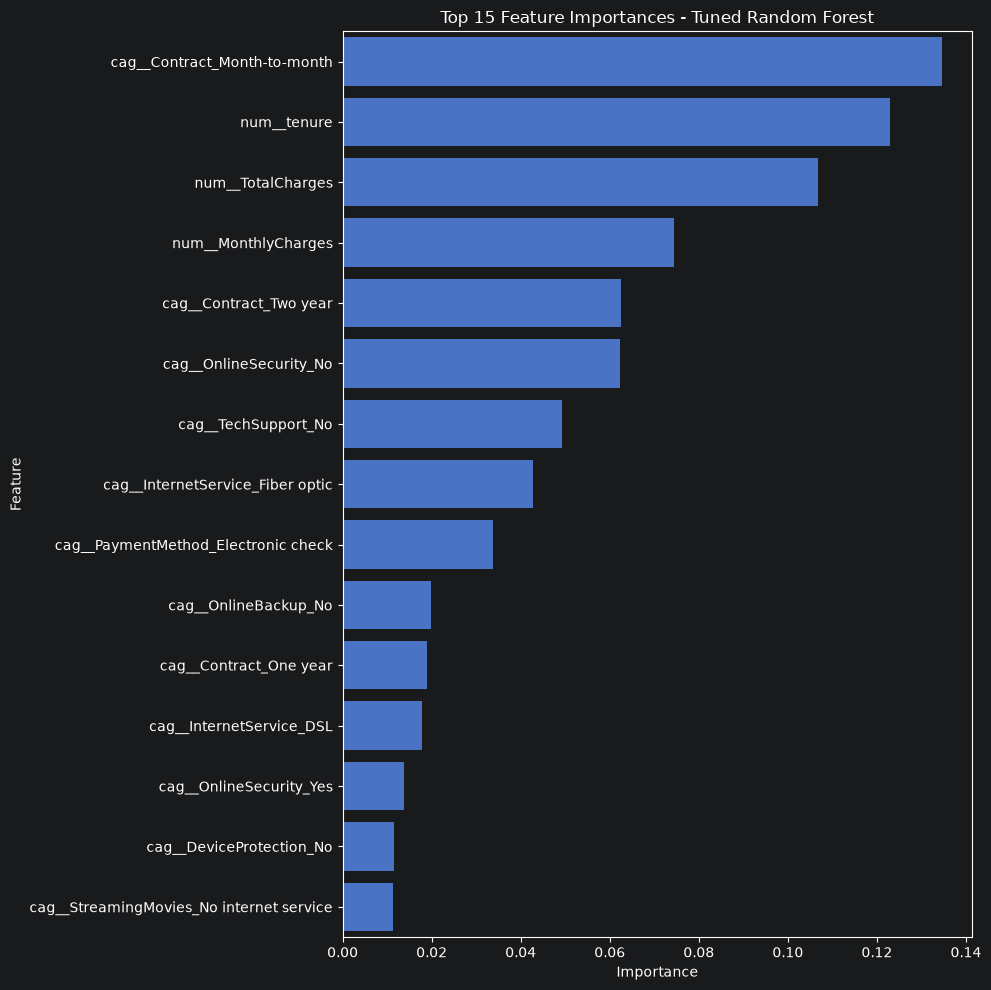

In [93]:
top_features = feature_importance.head(15)
plt.figure(figsize = (10,10))
sns.barplot(
    data = top_features,
    x= "Importance",
    y="Feature"
)
plt.title("Top 15 Feature Importances - Tuned Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [98]:
from sklearn.inspection import permutation_importance
f1_scorer = make_scorer(
    f1_score,
    pos_label = "Yes",
    zero_division = 0
)
perm_result = permutation_importance(
    rf_best_model,
    X_test,
    y_test,
    scoring = f1_scorer,
    n_repeats = 10,
    random_state = 42,
    n_jobs = -1
)

permutation_df = pd.DataFrame({
    "Feature" : X_test.columns,
    "Importance Mean" : perm_result.importances_mean,
    "Importance std" : perm_result.importances_std
})
permutation_df = permutation_df.sort_values(
    by = "Importance Mean",
    ascending = False
)
permutation_df.head(15)

,Feature,Importance Mean,Importance std
14,Contract,0.106851,0.018251
7,InternetService,0.040824,0.010055
4,tenure,0.023229,0.007553
18,TotalCharges,0.017780,0.003704
0,gender,0.002630,0.003684
8,OnlineSecurity,0.002611,0.005308
16,PaymentMethod,0.001854,0.004366
1,SeniorCitizen,0.001662,0.000992
11,TechSupport,0.001646,0.003919
3,Dependents,0.000334,0.002654
